# Section 2a: PyTorch MLP

ML4N - Group Project 4

This notebook trains the neural network detector (role A of `docs/project/SECTION2_RULES.md`). The model and the
training code are in `src/models.py`, here we only run them: first a detector for the group's app with fixed
hyperparameters (delivered early, Sections 3-4 start from it), then the cross-validation with the hyperparameter
search for the 10 apps, and finally the model with the best hyperparameters.

The design choices are explained in `docs/project/SECTION2_MLP_NOTES.md`.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# move to the project root, otherwise the relative paths in src/ don't work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
PLOTS_DIR = Path("results/plots")
MODELS_DIR = Path("results/models")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

from src.data import APPS, LogMinMaxScaler, load_train_test, make_ovr_target
from src.evaluation import SEED, compute_metrics, get_cv_folds, group_sample, plot_training_curve, save_cv_result
from src.models import get_device, predict, predict_proba, save_mlp, train_mlp

print("device:", get_device())

device: cuda


## 2.0 Data

Same data as the other classifiers: `load_train_test` loads `model_ready.csv` (Section 1, without the 3 redundant
features) and splits it 80/20 by `Flow.ID` with seed 42. `X_train` is not scaled: the scaler is fitted inside each
fold. `get_cv_folds` gives the 5 folds shared by all the models (grouped by `Flow.ID`, stratified on the app).

In [2]:
X_train, X_test, y_train, y_test, groups_train = load_train_test()
folds = get_cv_folds(y_train, groups_train)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, folds: {len(folds)}")

X_train: (403879, 64), X_test: (100970, 64), folds: 5


### The group's app

Group AD: counting the letters like spreadsheet columns, AD = 30 and 30 mod 10 = 0, the first app of the list:
**YOUTUBE** (to be confirmed with the tutor). It is the biggest class (about 1/3 of the flows), so the imbalance is
mild compared to the other apps, but from the EDA it is one of the hardest to separate: the best single feature has
AUC ~0.6, so a non-linear model is needed.

In [3]:
APP = "YOUTUBE"
y_bin = make_ovr_target(y_train, APP)
print(f"{APP}: {y_bin.mean():.1%} of the training flows are class 1 ({y_bin.sum():,} of {len(y_bin):,})")

YOUTUBE: 33.8% of the training flows are class 1 (136,620 of 403,879)


## 2.1 First detector with fixed hyperparameters

Before the hyperparameter search, a first version of the detector for Sections 3-4 (they need a model to attack while
the cross-validation runs). The hyperparameters are a standard starting point, not tuned:

- `hidden=(64, 32)`: two hidden layers, 64 -> 64 -> 32 -> 2
- `lr=1e-3`: the default learning rate of Adam
- `batch_size=512`
- `class_weight="balanced"`: errors on the app weigh more than errors on the other apps, so the detector doesn't
  learn to say "class 0" too often (Section 3 needs a recall of class 1 well above 0)

To know when to stop (early stopping) we take 10% of the training set with `group_sample`: whole flows, stratified
on the app, so it has the same composition as the training set and no `Flow.ID` in common with it. The scaler
(log1p + Min-Max, as in Section 1) is fitted only on the remaining 90%, and the same scaler is saved with the model.

This is not a validation score: the early-stopping set is used to choose the number of epochs, so the F1 on it is
optimistic. The real validation is the cross-validation of 2.2.

In [4]:
params = dict(hidden=(64, 32), lr=1e-3, batch_size=512, class_weight="balanced")

(X_tr, yapp_tr, _), (X_es, yapp_es, _) = group_sample(X_train, y_train, groups_train, fraction=0.1)
y_tr, y_es = make_ovr_target(yapp_tr, APP).to_numpy(), make_ovr_target(yapp_es, APP).to_numpy()

scaler = LogMinMaxScaler().fit(X_tr)
X_tr_s, X_es_s = scaler.transform(X_tr), scaler.transform(X_es)
print(f"training: {len(X_tr):,} flows, early stopping: {len(X_es):,} flows "
      f"({y_tr.mean():.1%} and {y_es.mean():.1%} of class 1)")

t = time.time()
model, history = train_mlp(X_tr_s, y_tr, X_es_s, y_es, max_epochs=100, patience=5, **params)
print(f"{len(history['train_loss'])} epochs in {time.time() - t:.0f} s, best epoch: {history['best_epoch']}")

training: 363,491 flows, early stopping: 40,388 flows (33.8% and 33.8% of class 1)
25 epochs in 19 s, best epoch: 20


Training curve: the average loss per epoch on the training data and on the early-stopping set. The training loss
always goes down; the early-stopping loss stops improving at the dashed line, and those are the weights we keep.

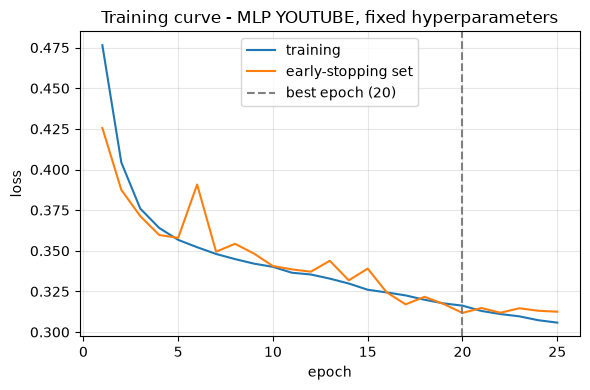

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_training_curve(history["train_loss"], history["es_loss"], history["best_epoch"], ax=ax)
ax.set_title(f"Training curve - MLP {APP}, fixed hyperparameters")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"mlp_{APP.lower()}_training_curve_v0.png", dpi=150)
plt.show()

Metrics on the early-stopping set (optimistic, see above) just to check that the detector works: recall of class 1
well above 0, as Section 3 requires, and F1 above the share of positives (what a random guess would get).

In [6]:
y_pred_es = predict(model, X_es_s)
y_score_es = predict_proba(model, X_es_s)
metrics_es = compute_metrics(y_es, y_pred_es, y_score_es)
pd.Series(metrics_es, name="early-stopping set").round(3).to_frame()

,early-stopping set
accuracy,0.844
precision,0.723
recall,0.871
f1,0.790
auc_roc,0.937
pr_auc,0.889


We save weights, architecture and scaler in `results/models/` with `save_mlp`. Sections 3-4 load them with
`load_mlp("results/models/mlp_youtube")` (see `SECTION2_MLP_NOTES.md`). The scaler saved here is the one fitted on
the 90% used for training, so the model and its scaler are consistent. This file is overwritten in 2.3 with the model
trained with the best hyperparameters.

In [7]:
save_mlp(model, scaler, MODELS_DIR / f"mlp_{APP.lower()}")
sorted(p.name for p in MODELS_DIR.glob(f"mlp_{APP.lower()}*"))

['mlp_youtube.json',
 'mlp_youtube.pt',
 'mlp_youtube_params.json',
 'mlp_youtube_scaler.joblib']

## 2.2 Cross-validation and hyperparameter search

`GridSearchCV` cannot train a PyTorch model, so the loop over the folds is written by hand, following the template
of `SECTION2_RULES.md`. For each fold:

1. the training part is split again with `group_sample`: 90% to train, 10% for early stopping (whole flows);
2. `LogMinMaxScaler` is fitted on that 90% only and applied to the 10% and to the validation fold;
3. `train_mlp` trains the network, `predict` labels the validation fold, and the F1 of class 1 is the score.

The validation score of a configuration is the mean F1 over the 5 folds, as for the other models. We also compute the
F1 on the training part (for the validation curve: training high and validation low = overfitting). `np.std` with
`ddof=0`, as `GridSearchCV` does for `std_test_score`.

Steps 1-2 do not depend on the app or on the configuration, so they are computed once per fold and kept in memory
(`get_fold_data`): `group_sample` is the slow step, about one minute per fold, more than a training.

Every (app, configuration) result is cached in `results/section2/mlp_grid.csv`, so the notebook can be re-run without
repeating the trainings.

In [8]:
from sklearn.metrics import f1_score

GRID_PATH = Path("results/section2/mlp_grid.csv")
GRID_PATH.parent.mkdir(parents=True, exist_ok=True)
ES_FRACTION = 0.1  # early-stopping set: 10% of the training part of each fold
_fold_data = {}    # fold number -> scaled arrays and app labels, filled by get_fold_data


def get_fold_data(i, folds):
    # Data of fold i, the same for every app and every configuration: the training part split again with
    # group_sample (90% training, 10% early stopping, whole flows), the scaler fitted on that 90% only,
    # and the three parts scaled. Computed the first time it is needed and then reused.
    if i not in _fold_data:
        train_idx, val_idx = folds[i]
        (X_tr, yapp_tr, _), (X_es, yapp_es, _) = group_sample(
            X_train.iloc[train_idx], y_train.iloc[train_idx], groups_train.iloc[train_idx], fraction=ES_FRACTION)
        scaler = LogMinMaxScaler().fit(X_tr)  # fitted only on the training part of the fold
        _fold_data[i] = {"X_tr": scaler.transform(X_tr).astype(np.float32),
                         "X_es": scaler.transform(X_es).astype(np.float32),
                         "X_val": scaler.transform(X_train.iloc[val_idx]).astype(np.float32),
                         "yapp_tr": yapp_tr, "yapp_es": yapp_es, "yapp_val": y_train.iloc[val_idx]}
    return _fold_data[i]


def cv_mlp(app, params, folds):
    # 5-fold cross-validation of one configuration for one app. Returns the mean/std validation F1,
    # the mean training F1, the mean epochs kept by early stopping, and the fit/predict times per fold.
    val_f1, train_f1, epochs, fit_times, predict_times = [], [], [], [], []
    for i in range(len(folds)):
        data = get_fold_data(i, folds)
        X_tr_s, X_es_s, X_val_s = data["X_tr"], data["X_es"], data["X_val"]
        y_tr = make_ovr_target(data["yapp_tr"], app).to_numpy()
        y_es = make_ovr_target(data["yapp_es"], app).to_numpy()
        y_val = make_ovr_target(data["yapp_val"], app).to_numpy()

        t = time.time()
        model, history = train_mlp(X_tr_s, y_tr, X_es_s, y_es, **params)
        fit_times.append(time.time() - t)
        t = time.time()
        y_pred = predict(model, X_val_s)
        predict_times.append(time.time() - t)

        val_f1.append(f1_score(y_val, y_pred))
        train_f1.append(f1_score(y_tr, predict(model, X_tr_s)))
        epochs.append(history["best_epoch"])
    return {"cv_f1_mean": np.mean(val_f1), "cv_f1_std": np.std(val_f1, ddof=0), "train_f1_mean": np.mean(train_f1),
            "best_epoch_mean": np.mean(epochs), "fit_time_s": np.mean(fit_times), "predict_time_s": np.mean(predict_times)}


def params_key(params):
    return json.dumps(params, sort_keys=True, default=str)


def run_config(app, params, folds):
    # cv_mlp with a cache on disk: one row per (app, params) in GRID_PATH
    grid = pd.read_csv(GRID_PATH) if GRID_PATH.exists() else pd.DataFrame()
    key = params_key(params)
    if len(grid) and ((grid["app"] == app) & (grid["params"] == key)).any():
        return grid[(grid["app"] == app) & (grid["params"] == key)].iloc[0].to_dict()
    row = {"app": app, "params": key, **params, **cv_mlp(app, params, folds)}
    row["hidden"] = str(params["hidden"])
    grid = pd.concat([grid, pd.DataFrame([row])], ignore_index=True)
    grid.to_csv(GRID_PATH, index=False)
    print(f"{app:15s} {key}  F1 = {row['cv_f1_mean']:.4f} +- {row['cv_f1_std']:.4f}  "
          f"(train {row['train_f1_mean']:.4f}, {row['best_epoch_mean']:.0f} epochs, {row['fit_time_s']:.0f} s/fold)")
    return row

### Grid search on the group's app

Full grid on YOUTUBE: 2 architectures x 2 learning rates x class weights on/off = 8 configurations x 5 folds.
Learning rates on a logarithmic scale, as the rules ask for parameters that span orders of magnitude.
`batch_size=512`, `max_epochs=100` and `patience=5` are fixed: the number of epochs is chosen by early stopping,
so it is not in the grid (Lecture 08: the epochs are a hyperparameter of the algorithm, tuned with the training
curve, not with the grid).

The full grid is run only on the group's app, the one attacked in Sections 3-4. For the 10 apps a smaller search is
done below, after the validation curve.

In [9]:
import ast
import itertools
import json

GRID = {"hidden": [(64, 32), (128, 64)], "lr": [1e-3, 1e-4], "class_weight": [None, "balanced"]}
FIXED = {"batch_size": 512, "max_epochs": 100, "patience": 5}

t_start = time.time()
for hidden, lr, cw in itertools.product(GRID["hidden"], GRID["lr"], GRID["class_weight"]):
    run_config(APP, {"hidden": hidden, "lr": lr, "class_weight": cw, **FIXED}, folds)
print(f"grid on {APP}: {(time.time() - t_start) / 60:.0f} min")

grid on YOUTUBE: 0 min


In [10]:
grid = pd.read_csv(GRID_PATH)
# only the 8 configurations of the grid: the cache also holds the rows added by the next steps
in_grid = (grid["app"] == APP) & grid["lr"].isin(GRID["lr"])
grid_app = grid[in_grid].sort_values("cv_f1_mean", ascending=False)
grid_app[["hidden", "lr", "class_weight", "cv_f1_mean", "cv_f1_std", "train_f1_mean", "best_epoch_mean", "fit_time_s"]].round(4)

,hidden,lr,class_weight,cv_f1_mean,cv_f1_std,train_f1_mean,best_epoch_mean,fit_time_s
5,"(128, 64)",0.0010,balanced,0.8106,0.0038,0.8145,33.4,15.5520
4,"(128, 64)",0.0010,NaN,0.8104,0.0106,0.8171,48.6,21.8589
1,"(64, 32)",0.0010,balanced,0.7988,0.0063,0.8007,40.0,19.1331
0,"(64, 32)",0.0010,NaN,0.7913,0.0053,0.7947,43.0,20.2061
6,"(128, 64)",0.0001,NaN,0.7901,0.0038,0.7937,87.2,36.1557
7,"(128, 64)",0.0001,balanced,0.7901,0.0026,0.7928,75.8,33.2167
3,"(64, 32)",0.0001,balanced,0.7835,0.0027,0.7853,98.0,39.7939
2,"(64, 32)",0.0001,NaN,0.7730,0.0050,0.7758,93.4,40.4064


Heatmap of the validation F1 for the two main hyperparameters (architecture x learning rate); in each cell the best
value over `class_weight`, as `plot_grid_heatmap` does for the sklearn models.

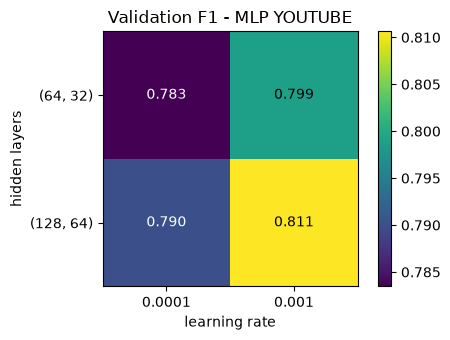

In [11]:
table = (grid_app.groupby(["hidden", "lr"])["cv_f1_mean"].max().unstack("lr"))
fig, ax = plt.subplots(figsize=(5, 3.5))
im = ax.imshow(table.to_numpy(), cmap="viridis", origin="lower")
ax.set_xticks(range(table.shape[1]), [f"{v:g}" for v in table.columns])
ax.set_yticks(range(table.shape[0]), table.index)
for (r, c), v in np.ndenumerate(table.to_numpy()):
    ax.text(c, r, f"{v:.3f}", ha="center", va="center", color="black" if v > table.to_numpy().mean() else "white")
ax.set_xlabel("learning rate")
ax.set_ylabel("hidden layers")
ax.set_title(f"Validation F1 - MLP {APP}")
plt.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"mlp_{APP.lower()}_grid_heatmap.png", dpi=150)
plt.show()

### Validation curve: learning rate

Training and validation F1 as a function of the learning rate (the other hyperparameters fixed at the best values),
on a logarithmic axis: the same plot as `plot_validation_curve` for the sklearn models, computed with `cv_mlp`.

best configuration of the grid on YOUTUBE : {'hidden': (128, 64), 'lr': 0.001, 'class_weight': 'balanced'}


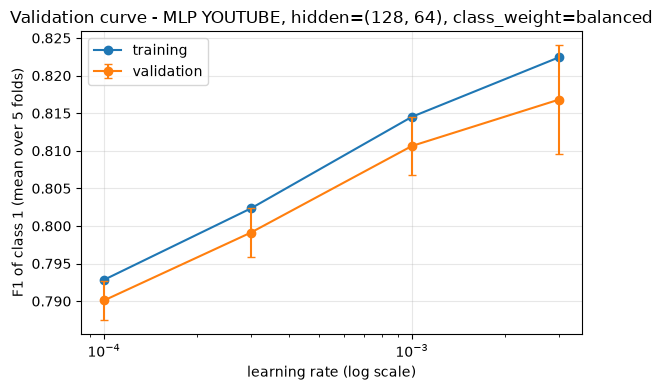

best lr on the curve: 0.003 (best lr in the grid: 0.001)


,lr,cv_f1_mean,cv_f1_std,train_f1_mean,best_epoch_mean,fit_time_s
0,0.0001,0.7901,0.0026,0.7928,75.8,33.2167
1,0.0003,0.7991,0.0032,0.8023,53.8,22.6614
2,0.0010,0.8106,0.0038,0.8145,33.4,15.5520
3,0.0030,0.8168,0.0073,0.8224,32.4,14.8594


In [12]:
best = grid_app.iloc[0]
best_params = {"hidden": ast.literal_eval(best["hidden"]),
               "lr": float(best["lr"]), "class_weight": None if pd.isna(best["class_weight"]) else best["class_weight"], **FIXED}
print("best configuration of the grid on", APP, ":", {k: best_params[k] for k in ["hidden", "lr", "class_weight"]})

LR_RANGE = [1e-4, 3e-4, 1e-3, 3e-3]
curve = [run_config(APP, {**best_params, "lr": lr}, folds) for lr in LR_RANGE]
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(LR_RANGE, curve["train_f1_mean"], marker="o", label="training")
ax.errorbar(LR_RANGE, curve["cv_f1_mean"], yerr=curve["cv_f1_std"], marker="o", capsize=3, label="validation")
ax.set_xscale("log")
ax.set_xlabel("learning rate (log scale)")
ax.set_ylabel("F1 of class 1 (mean over 5 folds)")
ax.set_title(f"Validation curve - MLP {APP}, hidden={best_params['hidden']}, class_weight={best_params['class_weight']}")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"mlp_{APP.lower()}_validation_curve_lr.png", dpi=150)
plt.show()
best_lr = float(curve.loc[curve["cv_f1_mean"].idxmax(), "lr"])
print(f"best lr on the curve: {best_lr:g} (best lr in the grid: {best_params['lr']:g})")
curve[["lr", "cv_f1_mean", "cv_f1_std", "train_f1_mean", "best_epoch_mean", "fit_time_s"]].round(4)

### Learning rate and class weights for the 10 apps

The architecture is the one chosen on YOUTUBE. For every app (YOUTUBE included) we try the two best learning rates
found above (the best of the grid and the best of the curve) with `class_weight ∈ {None, balanced}`: 4 configurations
per app, and the best one is kept. `class_weight` is the hyperparameter that really depends on the app, because the
share of positives goes from 3% to 34%. A full grid per app would cost ~10x more for models nobody attacks. For every
app the best configuration is written in `results/section2/mlp.csv` with `save_cv_result`, the format shared with the
other classifiers.


In [13]:
LRS = sorted({best_params["lr"], best_lr})  # best of the grid and best of the curve
t_start = time.time()
for app in APPS:
    for lr, cw in itertools.product(LRS, [None, "balanced"]):
        run_config(app, {**best_params, "lr": lr, "class_weight": cw}, folds)
print(f"lr in {LRS} x class_weight on the 10 apps: {(time.time() - t_start) / 60:.0f} min")

lr in [0.001, 0.003] x class_weight on the 10 apps: 0 min


In [14]:
grid = pd.read_csv(GRID_PATH)
# best cached row per app: for YOUTUBE over the grid, the lr curve and the 4 rows above, for the others over those 4 rows
best_rows = grid.sort_values("cv_f1_mean", ascending=False).groupby("app").head(1).set_index("app").loc[APPS]
for app, row in best_rows.iterrows():
    params = {"hidden": ast.literal_eval(row["hidden"]), "lr": float(row["lr"]),
              "class_weight": None if pd.isna(row["class_weight"]) else row["class_weight"], **FIXED,
              "early_stopping": f"{ES_FRACTION:.0%} group_sample of the training part, patience {FIXED['patience']}"}
    lrs = ", ".join(f"{lr:g}" for lr in LRS)
    notes = (f"full grid (hidden, lr, class_weight) + lr curve + lr in {{{lrs}}} x class_weight" if app == APP
             else f"hidden tuned on {APP}; lr in {{{lrs}}} and class_weight tuned per app")
    save_cv_result("mlp", app, best_params=params, cv_f1_mean=row["cv_f1_mean"], cv_f1_std=row["cv_f1_std"],
                   fit_time=row["fit_time_s"], predict_time=row["predict_time_s"], notes=notes)

share = y_train.value_counts(normalize=True)
summary = best_rows[["class_weight", "cv_f1_mean", "cv_f1_std", "train_f1_mean", "best_epoch_mean", "fit_time_s"]].copy()
summary.insert(0, "share_class1", share.loc[summary.index].round(3))
summary["class_weight"] = summary["class_weight"].fillna("None")
summary.round(4)

,share_class1,class_weight,cv_f1_mean,cv_f1_std,train_f1_mean,best_epoch_mean,fit_time_s
app,,,,,,,
YOUTUBE,0.338,None,0.8183,0.0065,0.8260,44.4,26.6563
AMAZON,0.172,None,0.8121,0.0083,0.8234,39.6,17.9673
GMAIL,0.080,None,0.5898,0.0077,0.6032,43.6,18.9624
WINDOWS_UPDATE,0.068,None,0.8037,0.0139,0.8111,36.6,16.4213
MICROSOFT,0.108,None,0.5853,0.0069,0.5961,35.2,16.3035
FACEBOOK,0.057,None,0.8681,0.0084,0.8732,35.8,15.7363
DROPBOX,0.050,None,0.8452,0.0193,0.8553,31.0,14.1689
SKYPE,0.061,None,0.5238,0.0074,0.5474,40.0,18.5716
TWITTER,0.036,None,0.2652,0.0297,0.2815,34.6,15.4229


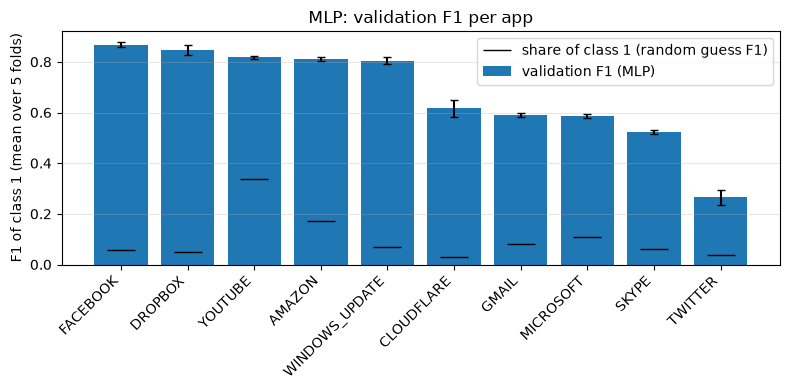

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
order = summary.sort_values("cv_f1_mean", ascending=False).index
ax.bar(order, summary.loc[order, "cv_f1_mean"], yerr=summary.loc[order, "cv_f1_std"], capsize=3, label="validation F1 (MLP)")
ax.plot(order, summary.loc[order, "share_class1"], "k_", markersize=20, label="share of class 1 (random guess F1)")
ax.set_ylabel("F1 of class 1 (mean over 5 folds)")
ax.set_title("MLP: validation F1 per app")
plt.xticks(rotation=45, ha="right")
ax.grid(True, alpha=0.3, axis="y")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "mlp_validation_f1_per_app.png", dpi=150)
plt.show()

Effect of the class weights: validation F1 without and with `class_weight="balanced"`, for every app at its best
learning rate (same architecture). Read from the cache, no training. A difference smaller than `cv_f1_std` is a tie.


In [16]:
rows = grid[(grid["hidden"] == best_rows.loc[APP, "hidden"]) & (grid["lr"] == grid["app"].map(best_rows["lr"]))].copy()
rows["class_weight"] = rows["class_weight"].fillna("None")
compare = rows.pivot(index="app", columns="class_weight", values="cv_f1_mean").loc[APPS, ["None", "balanced"]]
compare.columns.name = None
compare["balanced - None"] = compare["balanced"] - compare["None"]
compare["cv_f1_std"] = best_rows["cv_f1_std"]  # std of the best row of the app
compare.insert(0, "lr", best_rows["lr"])
compare.insert(0, "share_class1", summary["share_class1"])
compare.round(4)

,share_class1,lr,None,balanced,balanced - None,cv_f1_std
app,,,,,,
YOUTUBE,0.338,0.003,0.8183,0.8168,-0.0015,0.0065
AMAZON,0.172,0.003,0.8121,0.7760,-0.0361,0.0083
GMAIL,0.080,0.001,0.5898,0.4589,-0.1309,0.0077
WINDOWS_UPDATE,0.068,0.001,0.8037,0.6743,-0.1294,0.0139
MICROSOFT,0.108,0.003,0.5853,0.5173,-0.0680,0.0069
FACEBOOK,0.057,0.001,0.8681,0.6351,-0.2330,0.0084
DROPBOX,0.050,0.003,0.8452,0.6339,-0.2113,0.0193
SKYPE,0.061,0.001,0.5238,0.3718,-0.1520,0.0074
TWITTER,0.036,0.001,0.2652,0.2002,-0.0650,0.0297


### Comments

- **Learning rate is the hyperparameter that matters.** `1e-4` is too small: (64, 32) reaches the 100-epoch cap,
  (128, 64) stops after 76-87 epochs, and both give the worst F1 at twice the time. The validation curve rises
  monotonically up to `3e-3`, the largest value tried, but the step from `1e-3` to `3e-3` (+0.006) is within one
  std, so we stopped there.
- **Model size helps a little**: (128, 64) beats (64, 32) by 0.01-0.02 F1 at the same learning rate. We did not go
  bigger: the model is attacked in Sections 3-4 and training F1 is already within 0.01 of validation F1 (no
  overfitting, early stopping on the held-out 10% is enough, no dropout / weight decay needed).
- **`class_weight="balanced"` does not improve F1 on any app.** On YOUTUBE (33.8% positives) it makes no difference
  with the chosen architecture: 0.818 unweighted vs 0.817 balanced at `3e-3`, 0.810 vs 0.811 at `1e-3`, all inside
  one std. It only helped the small network (+0.01). On the other apps it hurts, badly for the rare ones (FACEBOOK
  0.87 -> 0.64): with few positives the balanced weights push the model to predict the app far more often, recall
  rises, precision collapses, and F1 (harmonic mean, threshold 0.5) drops. The rule is the highest validation F1,
  so the final YOUTUBE model is the unweighted one; the balanced variant is a tie with more recall and less precision.
- **Difficulty follows Section 1**: apps with a distinctive traffic profile (FACEBOOK, DROPBOX, YOUTUBE, AMAZON,
  WINDOWS_UPDATE) reach F1 >= 0.80; generic encrypted short flows (TWITTER, SKYPE, MICROSOFT, GMAIL) stay at 0.27-0.59.
- Cost: ~1.5-2 min of training per configuration (5 folds) on GPU, plus ~7 min once per session to build the data of
  the 5 folds; all CV results are cached in `results/section2/mlp_grid.csv`, so rerunning the notebook does not
  retrain them.


## 2.3 Final model for the group's app

The detector with the best hyperparameters, trained on the whole training set (with the same 10% early-stopping
split as in 2.1) and saved in `results/models/`, overwriting the v0 of 2.1. This is the model of Sections 3-4.

final hyperparameters: {'hidden': (128, 64), 'lr': 0.003, 'class_weight': None, 'batch_size': 512}
44 epochs in 27 s, best epoch: 39


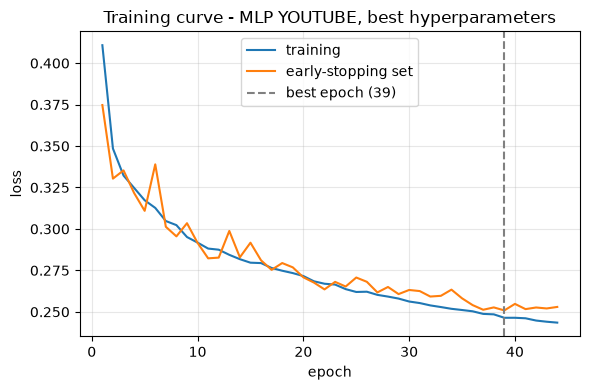

['mlp_youtube.json',
 'mlp_youtube.pt',
 'mlp_youtube_params.json',
 'mlp_youtube_scaler.joblib']

In [17]:
best_app = best_rows.loc[APP]  # the configuration written in mlp.csv for the group's app
final_params = {"hidden": ast.literal_eval(best_app["hidden"]), "lr": float(best_app["lr"]),
                "class_weight": None if pd.isna(best_app["class_weight"]) else best_app["class_weight"],
                "batch_size": FIXED["batch_size"]}
print("final hyperparameters:", final_params)

(X_tr, yapp_tr, _), (X_es, yapp_es, _) = group_sample(X_train, y_train, groups_train, fraction=ES_FRACTION)
y_tr, y_es = make_ovr_target(yapp_tr, APP).to_numpy(), make_ovr_target(yapp_es, APP).to_numpy()
scaler = LogMinMaxScaler().fit(X_tr)
X_tr_s, X_es_s = scaler.transform(X_tr), scaler.transform(X_es)

t = time.time()
model, history = train_mlp(X_tr_s, y_tr, X_es_s, y_es, max_epochs=FIXED["max_epochs"], patience=FIXED["patience"], **final_params)
print(f"{len(history['train_loss'])} epochs in {time.time() - t:.0f} s, best epoch: {history['best_epoch']}")

fig, ax = plt.subplots(figsize=(6, 4))
plot_training_curve(history["train_loss"], history["es_loss"], history["best_epoch"], ax=ax)
ax.set_title(f"Training curve - MLP {APP}, best hyperparameters")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"mlp_{APP.lower()}_training_curve_final.png", dpi=150)
plt.show()

save_mlp(model, scaler, MODELS_DIR / f"mlp_{APP.lower()}")
with open(MODELS_DIR / f"mlp_{APP.lower()}_params.json", "w") as f:
    json.dump({**final_params, **{k: FIXED[k] for k in ["max_epochs", "patience"]}, "best_epoch": history["best_epoch"],
               "cv_f1_mean": float(best_rows.loc[APP, "cv_f1_mean"]), "cv_f1_std": float(best_rows.loc[APP, "cv_f1_std"])}, f, indent=1, default=str)
sorted(p.name for p in MODELS_DIR.glob(f"mlp_{APP.lower()}*"))

### Test set (informational)

The rules of Section 2 say that the test set is used once, on the classifier with the best **validation** F1 among
the three (chosen by C with `compare_models`). The test scores of the other models can be reported as information
only, so here are the test metrics of the final MLP for YOUTUBE: they do not enter any decision. The scaler is the one
fitted on the training part, the test flows are only transformed (Lecture 07).

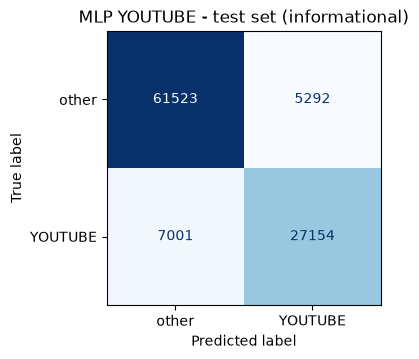

,test set
accuracy,0.878
precision,0.837
recall,0.795
f1,0.815
auc_roc,0.954
pr_auc,0.919


In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_bin = make_ovr_target(y_test, APP).to_numpy()
X_test_s = scaler.transform(X_test)
y_pred_test, y_score_test = predict(model, X_test_s), predict_proba(model, X_test_s)
metrics_test = compute_metrics(y_test_bin, y_pred_test, y_score_test)

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test_bin, y_pred_test, display_labels=["other", APP], cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"MLP {APP} - test set (informational)")
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"mlp_{APP.lower()}_confusion_test.png", dpi=150)
plt.show()
pd.Series(metrics_test, name="test set").round(3).to_frame()